# Temporal structure diagnostics for `try.ipynb`

This companion notebook examines the same 13 generation sources and leaves `try.ipynb` and the CSV unchanged. Results describe the provided data, not verified causal explanations. Generation units have not been verified, so axes use “dataset units”.

The original hourly / trailing 7-day plots distinguish high-frequency variability from slower movement. A 7-day rolling mean smooths daily and weekly variation; repeating wiggles alone do not establish seasonality. Here, **month-of-year seasonality means a cycle repeating every year**, not a 30-day cycle.

Main findings:

- Solar has the clearest annual and daily structure. Run-of-river hydro also has a repeatable spring-high / autumn-low annual profile.
- Reservoir hydro, gas and coal show daily and weekday patterns. Nuclear is relatively flat within a day, with recurring longer dips; maintenance is a hypothesis, not a confirmed cause.
- Biomass falls to a lower baseline around 2016; waste and other renewable rise. These level changes are different from seasonal repetition.
- **Calendar integrity needs investigation:** days 1–12 have anomalously flattened month-of-year profiles. A diagnostic month/day swap improves solar and river coherence substantially. This is strong evidence consistent with an upstream date/value misalignment, not authorization to rewrite dates.
- Wind has a broad winter/spring-high tendency, but its exact monthly shape varies substantially between years.

Do not treat exploratory scores below as formal significance tests or validated forecast accuracy. There are only four annual cycles.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf

DATA = Path('energy_dataset.csv')
assert DATA.exists(), 'Run this notebook from the data-anlysis project directory.'
raw = pd.read_csv(DATA)
raw['time'] = pd.to_datetime(raw['time'], utc=True)
raw = raw.set_index('time').sort_index()
assert raw.index.equals(pd.date_range(raw.index.min(), raw.index.max(), freq='h'))

supply = raw.filter(regex=r'^generation').drop(
    columns='generation hydro pumped storage consumption'
)
supply = supply.loc[:, (supply.notna() & supply.ne(0)).any()]
supply.columns = supply.columns.str.removeprefix('generation ')

# Calendar profiles use mainland Spain time, inferred from the dataset cities.
# UTC stays the equally spaced clock for row-based hourly lag diagnostics.
local = supply.tz_convert('Europe/Madrid')
daily = local.resample('D').mean()
monthly = local.resample('MS').mean()

print(f'{len(supply):,} hourly rows; {supply.shape[1]} active generation sources')
print('Local date range:', local.index.min(), 'to', local.index.max())
print('All-NaN rows:', int(supply.isna().all(axis=1).sum()))
display(local.groupby(local.index.year).mean().round(1).T)

# Flag only: simultaneous zero values are suspicious, not automatically missing.
zero_flags = supply.eq(0).sum(axis=1) >= 10
display(supply.loc[zero_flags])

35,064 hourly rows; 13 active generation sources
Local date range: 2015-01-01 00:00:00+01:00 to 2018-12-31 23:00:00+01:00
All-NaN rows: 17


time,2015,2016,2017,2018
biomass,491.4,365.5,340.5,336.9
fossil brown coal/lignite,514.7,380.6,544.3,352.9
fossil gas,5057.2,5142.1,6473.7,5818.2
fossil hard coal,5348.3,3652.9,4334.1,3692.5
fossil oil,330.3,286.1,294.7,282.2
hydro run-of-river and poundage,873.8,1022.5,768.4,1223.5
hydro water reservoir,2531.0,3382.8,1603.4,2901.1
nuclear,6248.8,6378.2,6346.1,6082.1
other,78.0,60.3,49.3,53.4
other renewable,69.2,80.6,94.8,97.9


,biomass,fossil brown coal/lignite,fossil gas,fossil hard coal,fossil oil,hydro run-of-river and poundage,hydro water reservoir,nuclear,other,other renewable,solar,waste,wind onshore
time,,,,,,,,,,,,,
2017-11-12 20:00:00+00:00,0.0,0.0,6899.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2017-11-14 11:00:00+00:00,0.0,0.0,10064.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2017-11-14 18:00:00+00:00,0.0,0.0,12336.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## 1. Compare the same calendar months across separate years

Each thin line is a year; the black line is the equal-year average monthly profile. A recurring shape across years supports annual seasonality. A vertical shift between years suggests a changing baseline. Monthly **means** avoid mechanically making 31-day months larger than shorter months. Missing hours are omitted rather than imputed.

These profiles use the supplied dates and remain provisional until the calendar issue in section 2 is resolved.

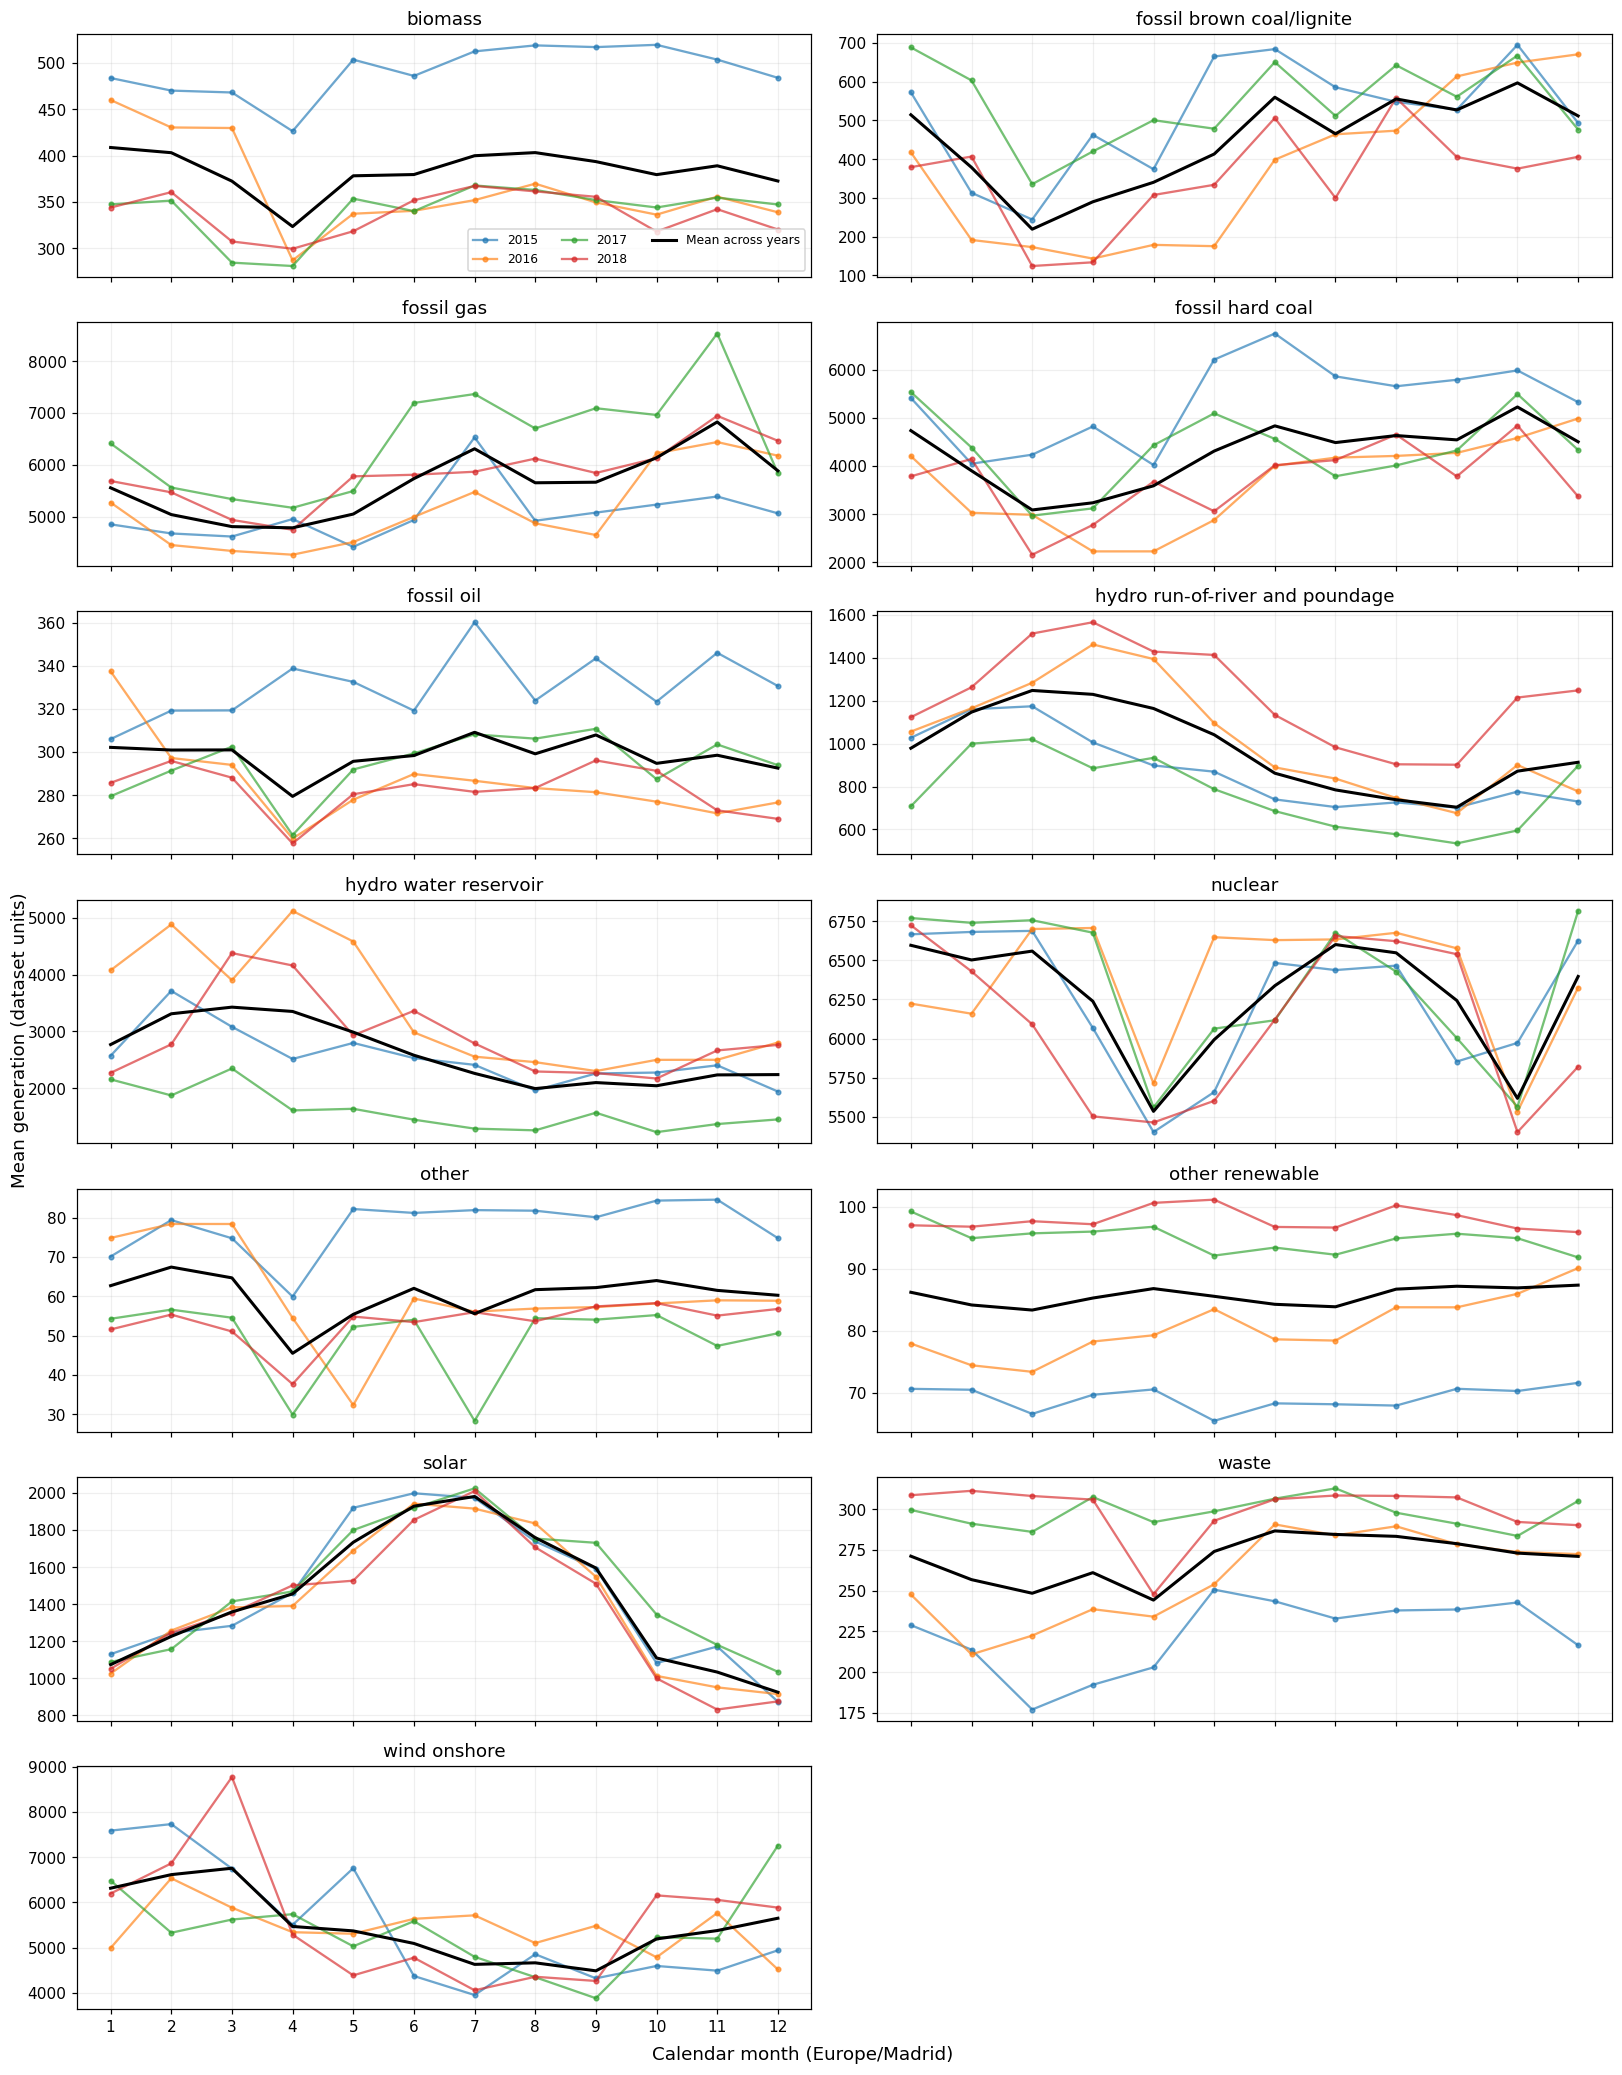

,mean_year_pair_correlation,minimum_year_pair_correlation,peak_month_pooled,trough_month_pooled
source,,,,
solar,0.948,0.925,7,12
hydro run-of-river and poundage,0.770,0.649,3,10
fossil gas,0.606,0.326,11,4
fossil brown coal/lignite,0.564,0.475,11,3
hydro water reservoir,0.551,0.373,3,8
nuclear,0.532,0.323,8,5
fossil hard coal,0.478,0.380,11,3
biomass,0.408,-0.002,1,4
other,0.299,-0.221,2,4


In [ ]:
fig, axes = plt.subplots(7, 2, figsize=(15, 19), sharex=True)
for ax, column in zip(axes.flat, supply.columns):
    profile = monthly[column].groupby(
        [monthly.index.year, monthly.index.month]
    ).mean().unstack()
    for year, values in profile.iterrows():
        ax.plot(values.index, values, marker='.', alpha=.65, label=str(year))
    ax.plot(profile.columns, profile.mean(), color='black', linewidth=2,
            label='Mean across years')
    ax.set_title(column)
    ax.set_xticks(range(1, 13))
    ax.grid(alpha=.2)
for ax in axes.flat[len(supply.columns):]:
    ax.set_visible(False)
axes[0, 0].legend(ncol=3, fontsize=8)
fig.supxlabel('Calendar month (Europe/Madrid)')
fig.supylabel('Mean generation (dataset units)')
fig.tight_layout()
plt.show()

rows = []
for column in supply.columns:
    profile = monthly[column].groupby(
        [monthly.index.year, monthly.index.month]
    ).mean().unstack()
    correlations = profile.T.corr().to_numpy()
    pairs = correlations[np.triu_indices_from(correlations, k=1)]
    rows.append({
        'source': column,
        'mean_year_pair_correlation': pairs.mean(),
        'minimum_year_pair_correlation': pairs.min(),
        'peak_month_pooled': int(profile.mean().idxmax()),
        'trough_month_pooled': int(profile.mean().idxmin()),
    })
monthly_repeatability = pd.DataFrame(rows).set_index('source')
display(monthly_repeatability.round(3).sort_values(
    'mean_year_pair_correlation', ascending=False
))

## 2. Audit an apparent calendar artifact before forecasting

Solar monthly averages on days 1–12 stay near 1,360–1,543, while days 13 onward range from about 635 in December to 2,334 in July. River hydro shows a similar split. In the heatmaps below, the first 12 days behave differently from the later days; the distinction is not explained by the sparse NaN rows.

A possible explanation is month/day interchange upstream for ambiguous dates (both numbers <=12). The CSV timestamps themselves are valid ISO strings and the notebook's UTC parsing is not evidence of a parsing error. Check the dataset's provenance or an independent reference series before making any correction. The original values and timestamps remain unchanged here.

The two subsets are **diagnostic sensitivity checks**, not unbiased replacements for full monthly statistics. Days 13 onward are not a representative sample of an entire month.

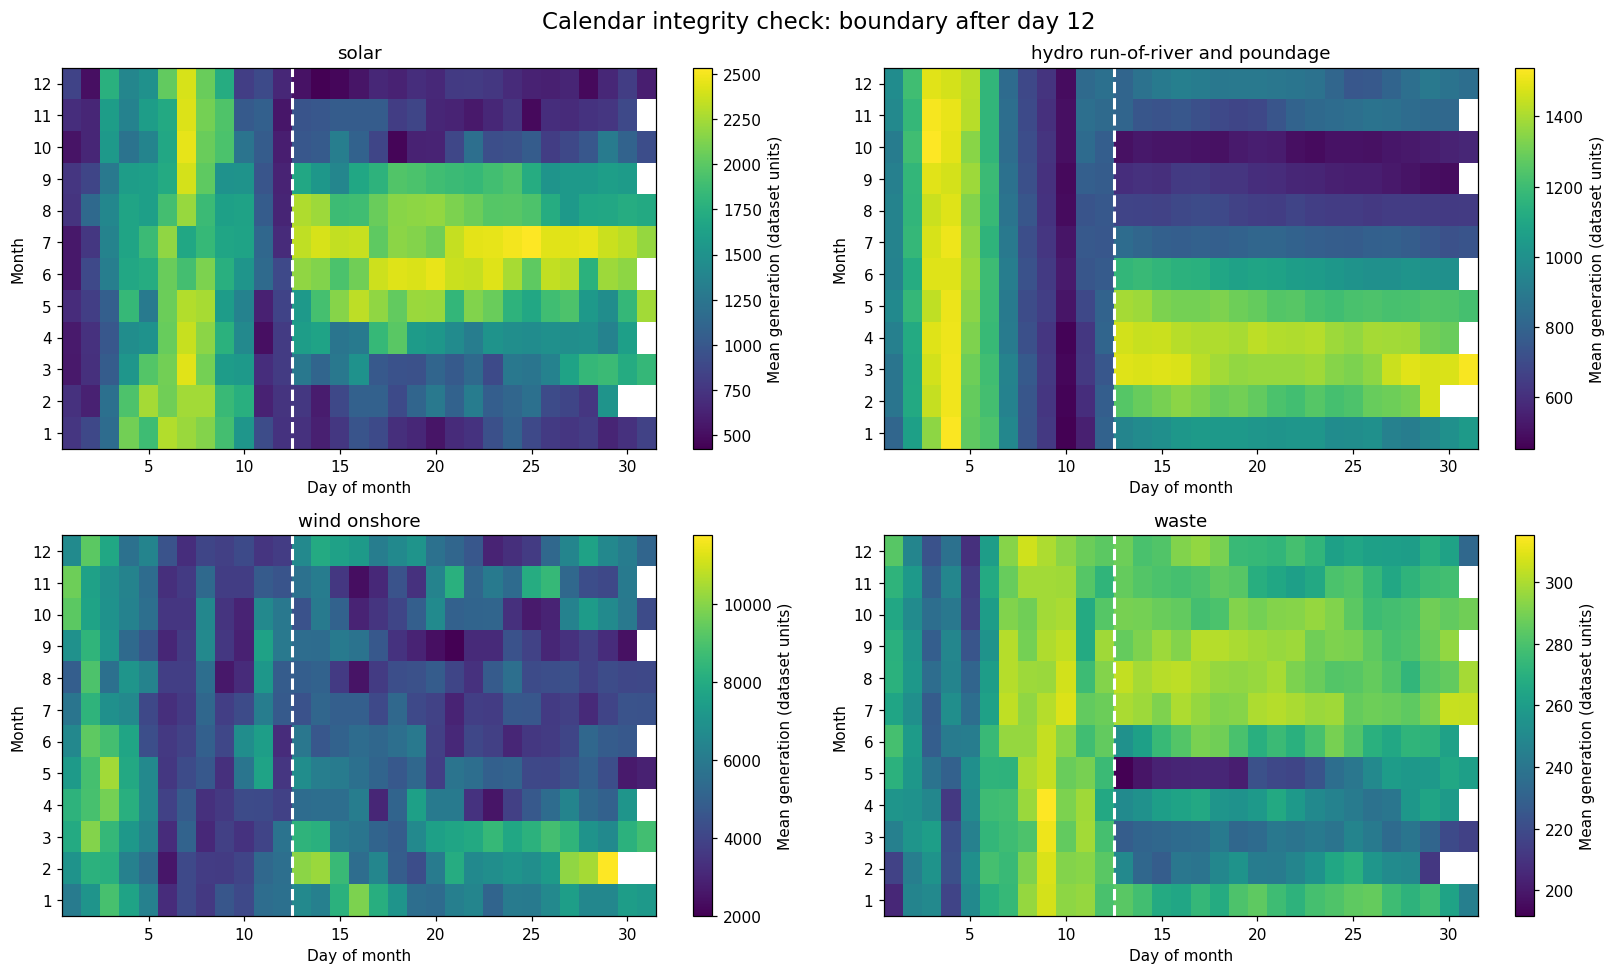

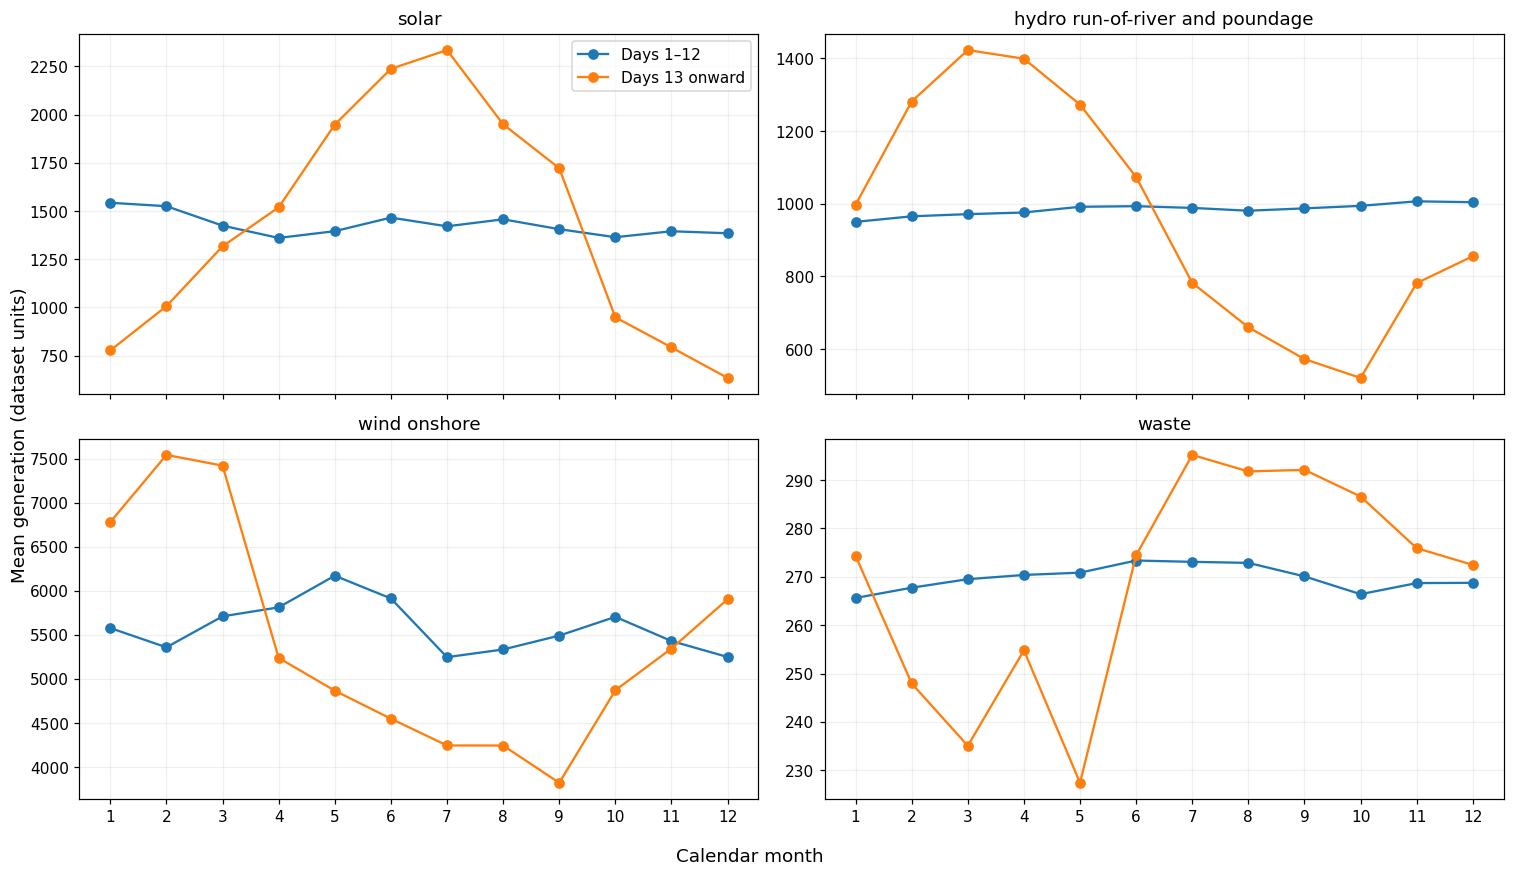

In [3]:
selected = ['solar', 'hydro run-of-river and poundage', 'wind onshore', 'waste']
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
for ax, column in zip(axes.flat, selected):
    calendar_grid = daily[column].groupby(
        [daily.index.month, daily.index.day]
    ).mean().unstack().reindex(index=range(1, 13), columns=range(1, 32))
    im = ax.imshow(calendar_grid, aspect='auto', origin='lower',
                   extent=(.5, 31.5, .5, 12.5), cmap='viridis')
    ax.axvline(12.5, color='white', linestyle='--', linewidth=2)
    ax.set(title=column, xlabel='Day of month', ylabel='Month', yticks=range(1, 13))
    fig.colorbar(im, ax=ax, label='Mean generation (dataset units)')
fig.suptitle('Calendar integrity check: boundary after day 12', fontsize=15)
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True)
for ax, column in zip(axes.flat, selected):
    for label, mask in [('Days 1–12', daily.index.day <= 12),
                        ('Days 13 onward', daily.index.day > 12)]:
        curve = daily.loc[mask, column].groupby(daily.index[mask].month).mean()
        ax.plot(curve.index, curve, marker='o', label=label)
    ax.set(title=column, xticks=range(1, 13))
    ax.grid(alpha=.2)
axes[0, 0].legend()
fig.supxlabel('Calendar month')
fig.supylabel('Mean generation (dataset units)')
fig.tight_layout()
plt.show()

The next calculation tests a specific hypothesis without correcting any data. Fit a smooth annual profile (two Fourier harmonics plus year intercepts) using days 13 onward. On days 1–12, compare predictions using (a) supplied calendar dates and (b) hypothetical interchanged month/day labels. Lower error under (b) supports investigating the hypothesis. This is a retrospective diagnostic using full-history data, **not** an out-of-sample forecast experiment or proof of the correct date mapping.

In [4]:
def calendar_design(index):
    day = index.dayofyear.to_numpy()
    year = index.year.to_numpy()
    return np.column_stack([
        np.ones(len(index)),
        *[(year == value).astype(int) for value in sorted(daily.index.year.unique())[1:]],
        *[term for k in (1, 2) for term in (
            np.sin(2 * np.pi * k * day / 365.2425),
            np.cos(2 * np.pi * k * day / 365.2425)
        )]
    ])

unambiguous = daily.index.day > 12
ambiguous_dates = daily.index[~unambiguous]
hypothetical_dates = pd.DatetimeIndex([
    pd.Timestamp(year=t.year, month=t.day, day=t.month, tz='Europe/Madrid')
    for t in ambiguous_dates
])
hypothesis_rows = []
for column in selected:
    observed_train = daily.loc[unambiguous, column]
    valid = observed_train.notna().to_numpy()
    coefficients = np.linalg.lstsq(
        calendar_design(daily.index[unambiguous])[valid],
        observed_train.to_numpy()[valid], rcond=None
    )[0]
    actual = daily.loc[~unambiguous, column].to_numpy()
    errors = {}
    for label, dates in [('supplied_dates_RMSE', ambiguous_dates),
                         ('hypothetical_swap_RMSE', hypothetical_dates)]:
        predicted = calendar_design(dates) @ coefficients
        errors[label] = np.sqrt(np.nanmean((actual - predicted) ** 2))
    hypothesis_rows.append({'source': column, **errors})
calendar_hypothesis = pd.DataFrame(hypothesis_rows).set_index('source')
display(calendar_hypothesis.round(1))

,supplied_dates_RMSE,hypothetical_swap_RMSE
source,,
solar,912.7,473.8
hydro run-of-river and poundage,482.6,183.9
wind onshore,3374.2,2815.4
waste,44.3,32.0


## 3. Look below the 7-day average: daily and weekly profiles

Subtract each source's year-month mean before grouping by hour or weekday, so changing baselines do not dominate the comparison. Curves are expressed as percent of each source's overall mean. Grouping uses local civil time, including daylight saving. These are descriptive profiles and still inherit any upstream calendar artifact, particularly the weekday attribution.

Daily: solar dominates, followed by reservoir hydro and gas. Weekly: gas, coal/lignite and reservoir hydro have larger weekday/weekend contrasts. Nuclear is almost flat within the day. Do not infer causal dispatch behavior from a calendar profile alone.

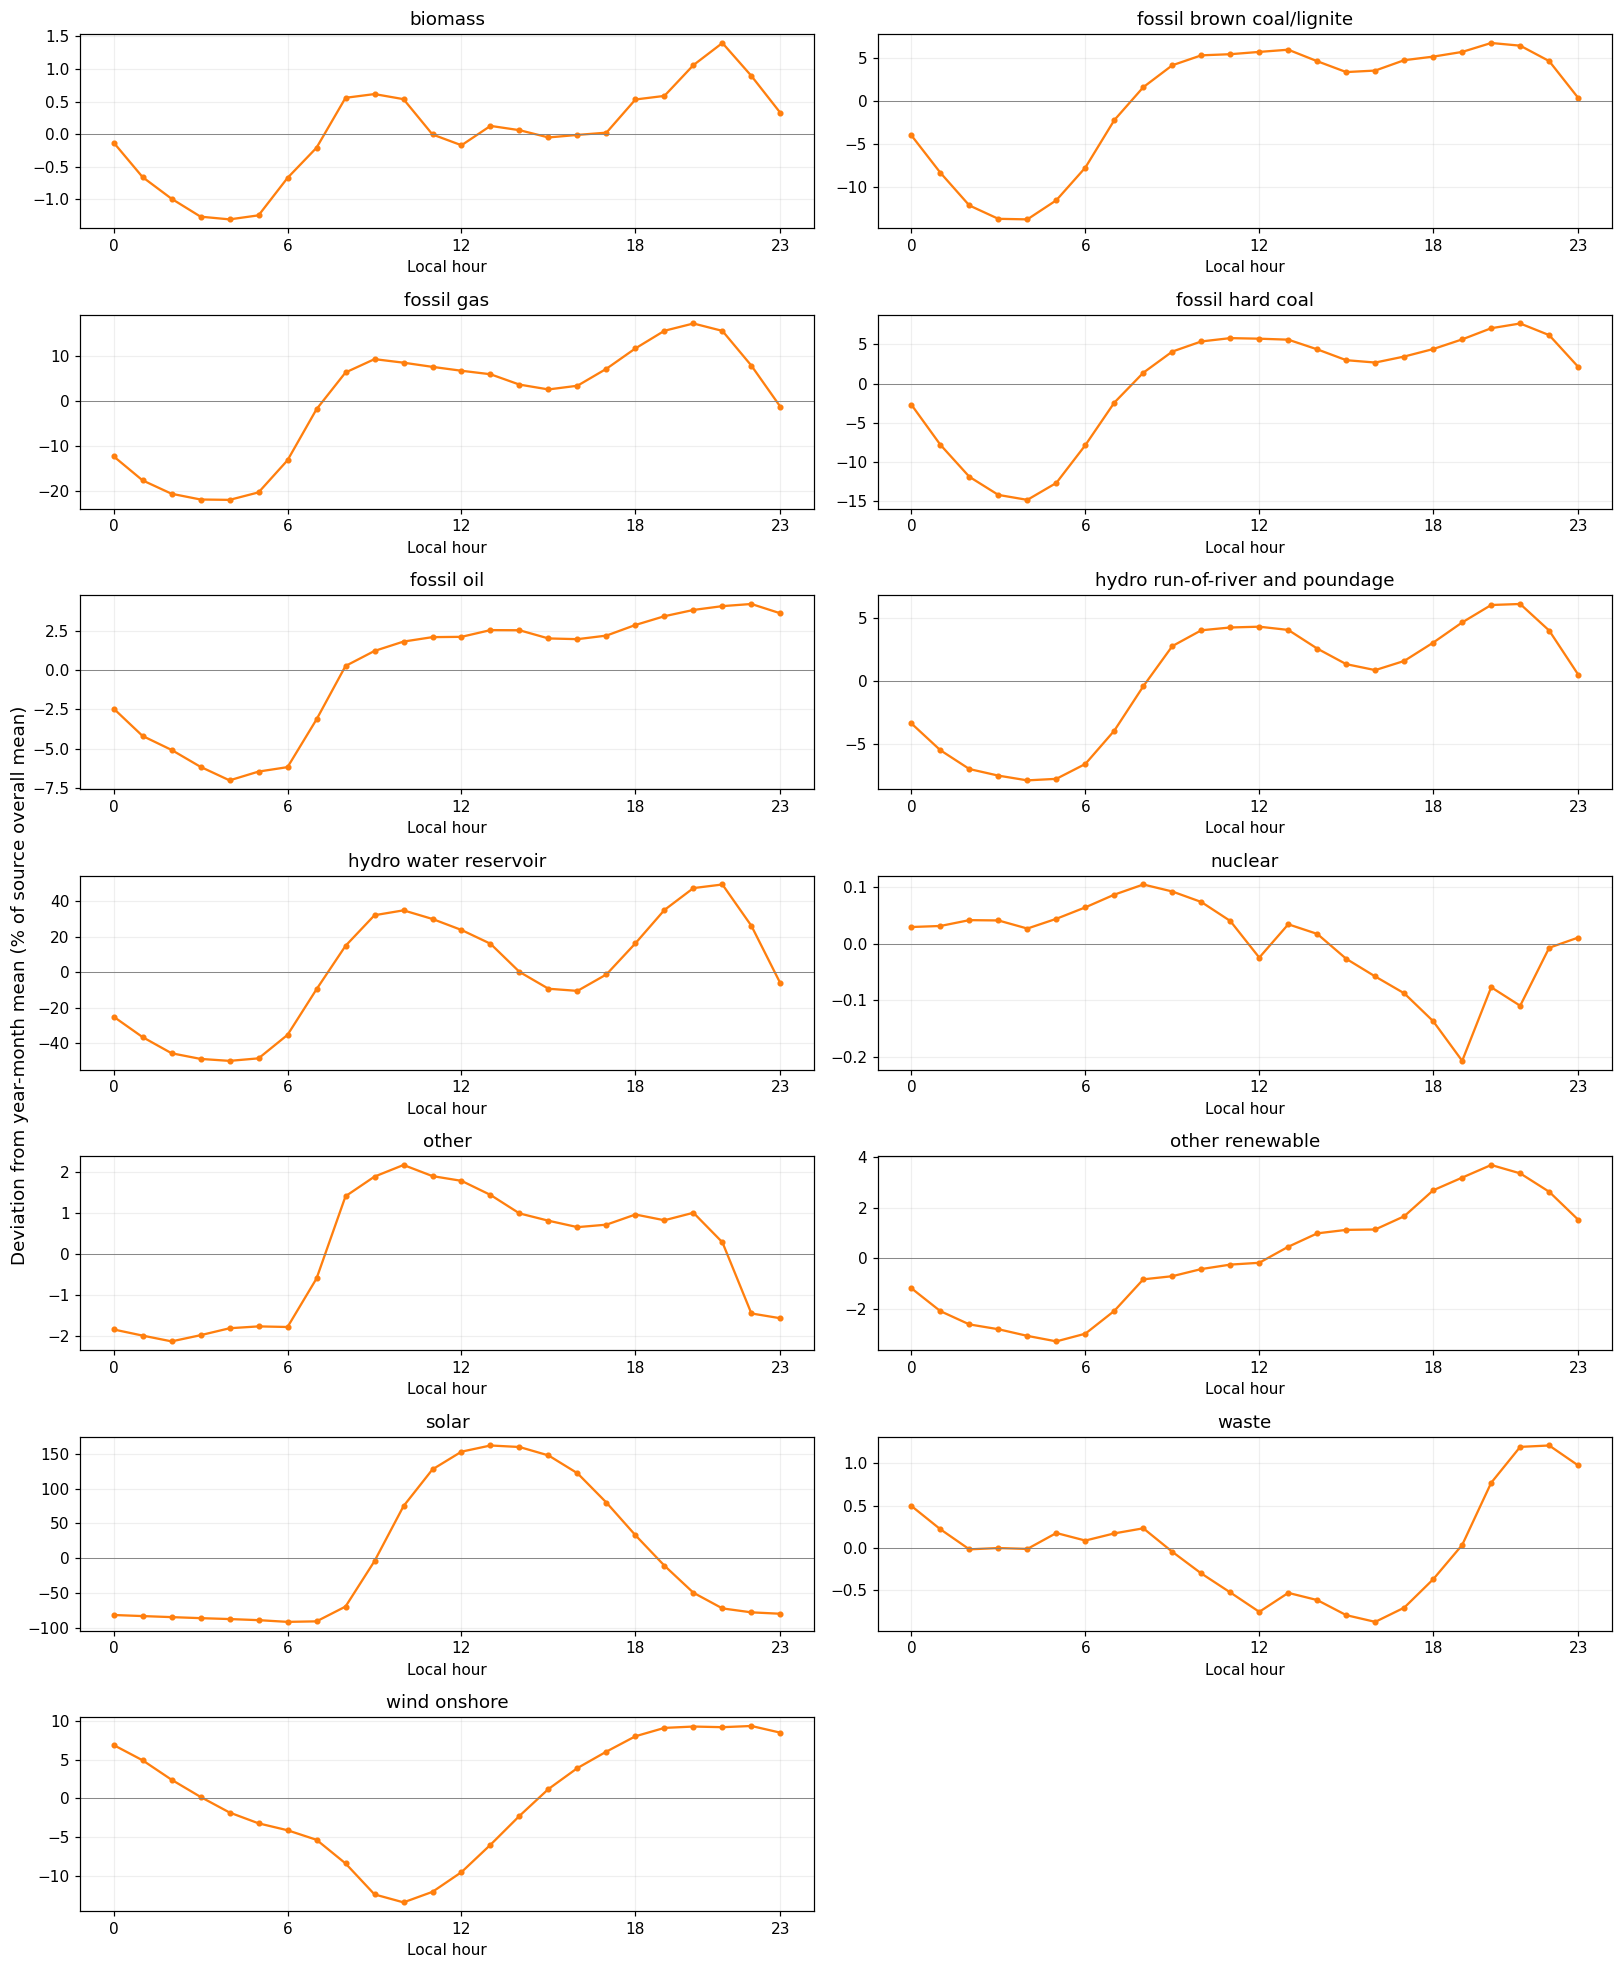

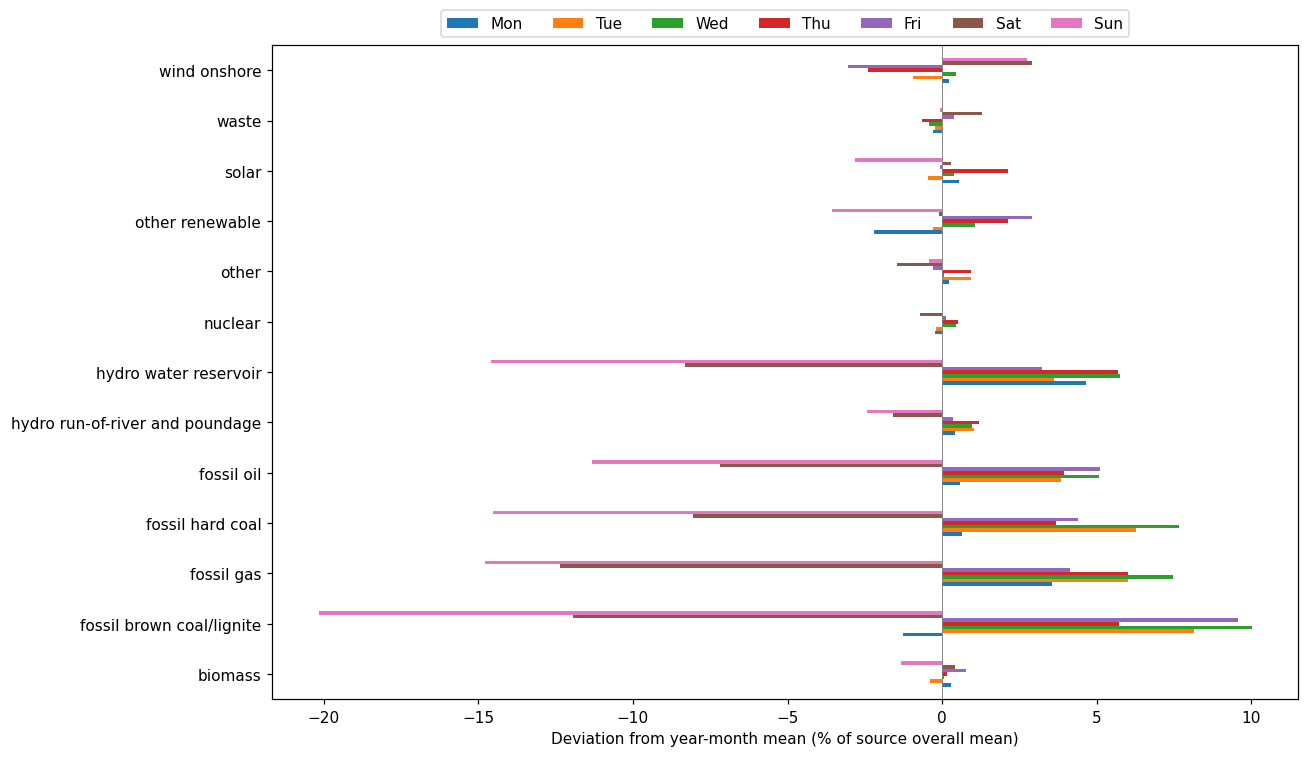

,mean_year_pair_correlation,minimum_year_pair_correlation,peak_month_pooled,trough_month_pooled,daily_profile_range_pct_mean,weekday_profile_range_pct_mean
source,,,,,,
biomass,0.408,-0.002,1,4,2.709,2.086
fossil brown coal/lignite,0.564,0.475,11,3,20.474,30.188
fossil gas,0.606,0.326,11,4,39.184,22.245
fossil hard coal,0.478,0.380,11,3,22.567,22.195
fossil oil,0.060,-0.619,7,4,11.217,16.459
hydro run-of-river and poundage,0.770,0.649,3,10,13.981,3.623
hydro water reservoir,0.551,0.373,3,8,99.249,20.347
nuclear,0.532,0.323,8,5,0.310,1.235
other,0.299,-0.221,2,4,4.311,2.392


In [5]:
centered = local - local.groupby([local.index.year, local.index.month]).transform('mean')
hour_profile = centered.groupby(centered.index.hour).mean().div(local.mean()) * 100
weekday_profile = centered.groupby(centered.index.dayofweek).mean().div(local.mean()) * 100

fig, axes = plt.subplots(7, 2, figsize=(15, 18))
for ax, column in zip(axes.flat, supply.columns):
    ax.plot(hour_profile.index, hour_profile[column], marker='.', color='tab:orange')
    ax.axhline(0, color='grey', linewidth=.6)
    ax.set(title=column, xticks=[0, 6, 12, 18, 23], xlabel='Local hour')
    ax.grid(alpha=.2)
for ax in axes.flat[len(supply.columns):]:
    ax.set_visible(False)
fig.supylabel('Deviation from year-month mean (% of source overall mean)')
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(12, 7))
weekday_profile.rename(index=dict(enumerate(['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']))).T.plot.barh(ax=ax)
ax.set(xlabel='Deviation from year-month mean (% of source overall mean)', ylabel='')
ax.axvline(0, color='grey', linewidth=.6)
ax.legend(ncol=7, loc='lower center', bbox_to_anchor=(.5, 1.0))
fig.tight_layout()
plt.show()

profile_summary = monthly_repeatability.copy()
profile_summary['daily_profile_range_pct_mean'] = hour_profile.max() - hour_profile.min()
profile_summary['weekday_profile_range_pct_mean'] = weekday_profile.max() - weekday_profile.min()
display(profile_summary.round(3))

## 4. Check autocorrelation after removing slower movement

Raw ACF can remain high simply because nearby observations share a changing baseline. For an exploratory daily/weekly diagnostic, subtract a centered 30-day rolling mean and examine lags around 24, 48 and 168 hours. The centered filter uses future values and is for visualization only. It must not be used as a prediction feature.

ACF requires a complete regular sequence. Fill only isolated internal gaps up to two hours for this diagnostic; leave longer gaps untouched, then use the longest complete segment. These temporary values never replace source data. Each source can select a different date window, shown in the table, so these curves describe selected windows and are not full-history source rankings. A weekly-looking lag is especially provisional while the calendar issue is unresolved.

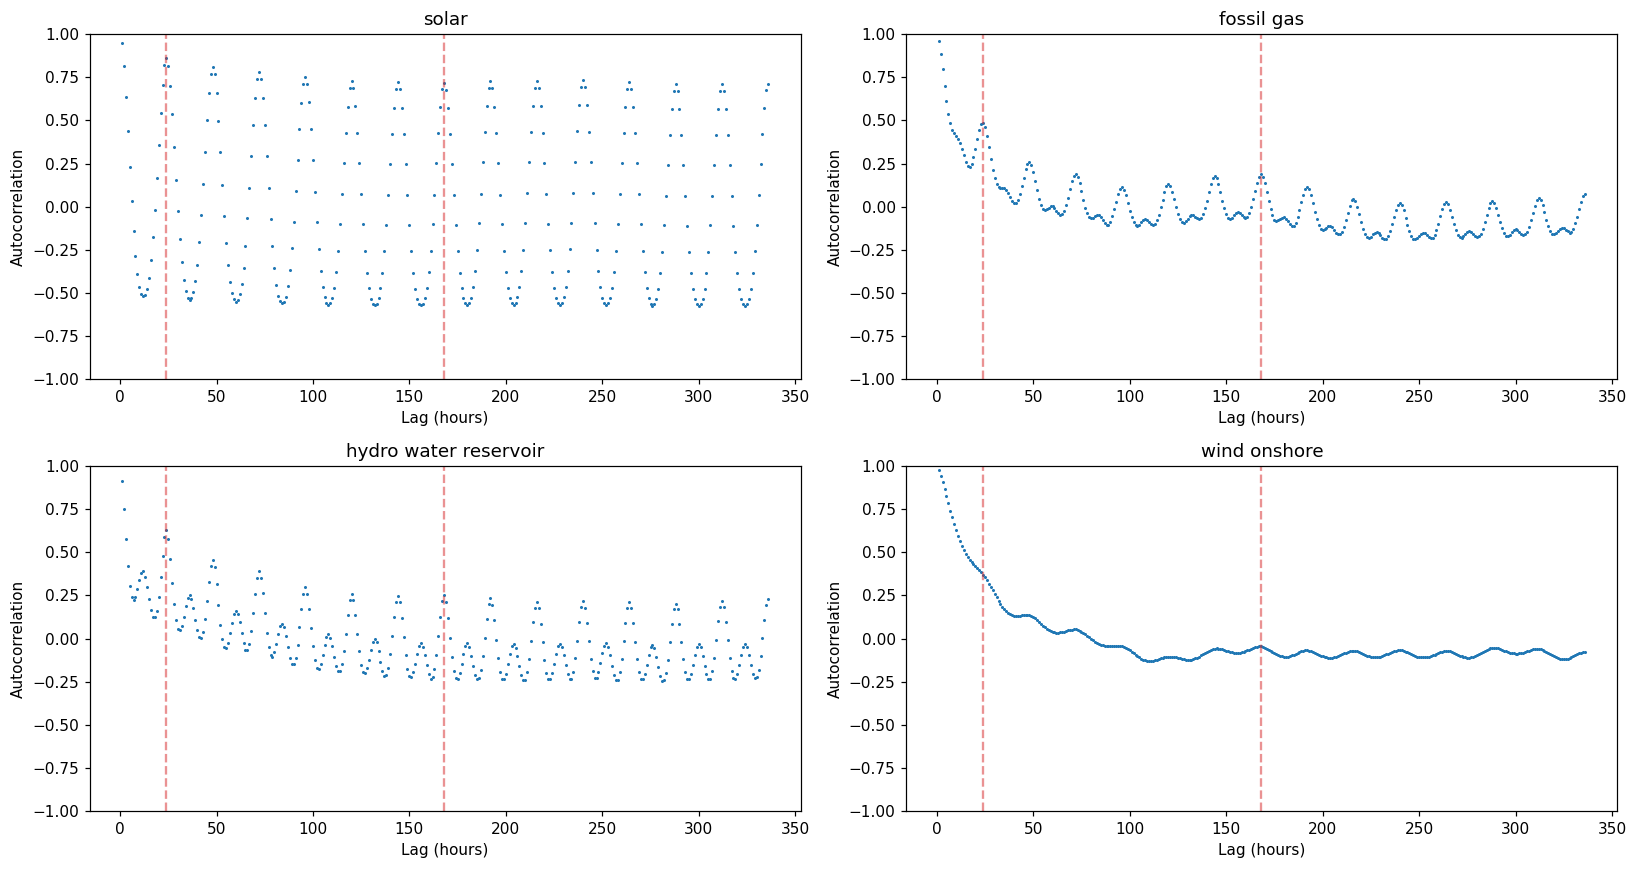

,segment_hours,segment_start,segment_end,lag_24,lag_168
source,,,,,
solar,34950,2015-01-05 17:00:00+00:00,2018-12-31 22:00:00+00:00,0.864,0.721
fossil gas,34950,2015-01-05 17:00:00+00:00,2018-12-31 22:00:00+00:00,0.487,0.189
hydro water reservoir,34950,2015-01-05 17:00:00+00:00,2018-12-31 22:00:00+00:00,0.629,0.251
wind onshore,34950,2015-01-05 17:00:00+00:00,2018-12-31 22:00:00+00:00,0.369,-0.044


In [6]:
acf_sources = ['solar', 'fossil gas', 'hydro water reservoir', 'wind onshore']
fig, axes = plt.subplots(2, 2, figsize=(15, 8))
acf_diagnostics = []
for ax, column in zip(axes.flat, acf_sources):
    series = supply[column]
    missing = series.isna()
    run = missing.ne(missing.shift(fill_value=False)).cumsum()
    run_length = missing.groupby(run).transform('sum')
    interpolated = series.interpolate(method='time', limit_area='inside')
    diagnostic = series.mask(missing & run_length.le(2), interpolated)
    residual = diagnostic - diagnostic.rolling('30D', center=True, min_periods=24*7).mean()
    valid = residual.notna()
    segments = valid.ne(valid.shift(fill_value=False)).cumsum()
    lengths = valid.groupby(segments).sum()
    longest = lengths.idxmax()
    segment = residual.loc[valid & segments.eq(longest)]
    assert len(segment) > 2 * 336
    plot_acf(segment, lags=336, ax=ax, zero=False, alpha=None, fft=True,
             title=column, use_vlines=False, marker='.', markersize=2)
    for lag in (24, 168):
        ax.axvline(lag, color='tab:red', linestyle='--', alpha=.5)
    ax.set(xlabel='Lag (hours)', ylabel='Autocorrelation')
    acf_diagnostics.append({'source': column, 'segment_hours': len(segment),
                            'segment_start': segment.index.min(),
                            'segment_end': segment.index.max(),
                            'lag_24': segment.autocorr(24), 'lag_168': segment.autocorr(168)})
fig.tight_layout()
plt.show()
display(pd.DataFrame(acf_diagnostics).set_index('source').round(3))

## Implications for forecasting

1. Investigate date/value alignment and the simultaneous-zero observations before deciding which timestamps can support reliable validation. Do not automatically relabel or delete observations based on these diagnostics.
2. After chronology is verified, choose a target and horizon, then compare persistence, same-hour-yesterday and same-hour-last-week baselines. Keep the UTC timeline regular; create hour, weekday and month features from local time.
3. Test hour-of-day, weekday, month / day-of-year and their cyclic encodings alongside lagged observations and trailing means computed only from values available at the forecast origin. A multi-step horizon may require recursive forecasts or different feature construction.
4. Solar and wind likely benefit from weather information; reservoir/river generation may need hydrological and operational information. These are modeling hypotheses to test, not causal findings from the plots.
5. Use chronological rolling-origin evaluation. A useful initial comparison is training on 2015–2016, validating on 2017, and reserving 2018 for the final evaluation, subject to verified timestamps. Fit preprocessing separately within each training window. Missing target observations should not be replaced by interpolated “truth” when scoring.
6. Consider STL with `period=12` on monthly means for an annual-cycle view, or MSTL with periods 24/168 on a verified hourly series. `period=12` on hourly data would mean a 12-hour cycle. Four years offer only four annual repetitions; decomposition alone cannot establish reliable future seasonality.

Sources: [Seasonal plots and ACF](https://otexts.com/fpp3/acf.html), [statsmodels STL](https://www.statsmodels.org/stable/examples/notebooks/generated/stl_decomposition.html), [time-series cross-validation](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.TimeSeriesSplit.html).